In [2]:

import pandas as pd

# Define column names
columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

# Load the dataset
df = pd.read_csv("iris.data", header=None, names=columns)

# Display the first five rows
print(df.head())

# Check the dataset
print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())


   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
Dataset shape: (150, 5)
Missing values: 0


In [3]:

# Analysis 1: Descriptive Statistics

statistics = df.groupby("species")["petal_length"].agg(
    count="count",
    mean="mean",
    variance="var",
    std_dev="std"
)

print("Petal Length Statistics by Species")
print(statistics.round(3))


Petal Length Statistics by Species
                 count   mean  variance  std_dev
species                                         
Iris-setosa         50  1.464     0.030    0.174
Iris-versicolor     50  4.260     0.221    0.470
Iris-virginica      50  5.552     0.305    0.552


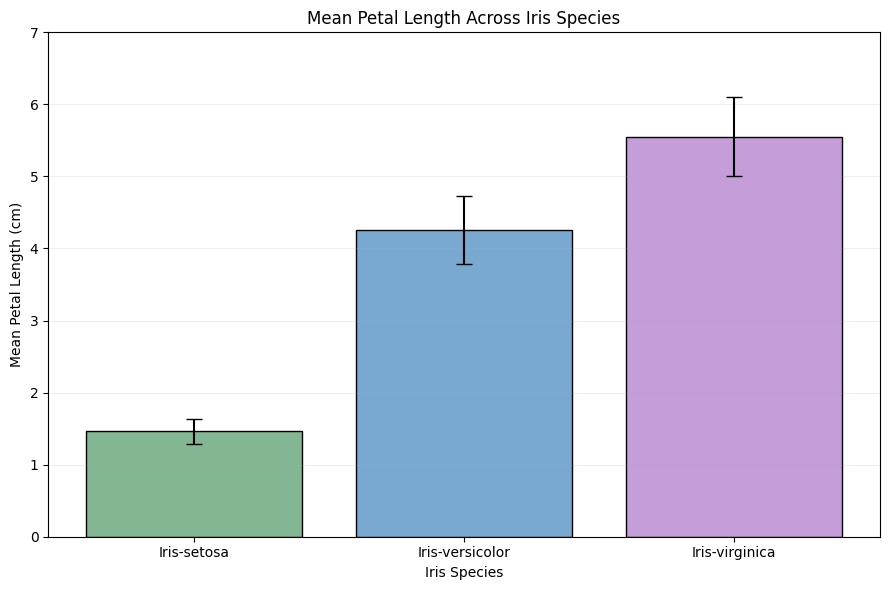

In [4]:

import matplotlib.pyplot as plt

# Figure 1: Mean petal length by species
species = statistics.index
means = statistics["mean"]
std_devs = statistics["std_dev"]

plt.figure(figsize=(9, 6))

plt.bar(
    species,
    means,
    yerr=std_devs,
    capsize=6,
    color=["#83B692", "#79A9D1", "#C59DD9"],
    edgecolor="black"
)

plt.title("Mean Petal Length Across Iris Species")
plt.xlabel("Iris Species")
plt.ylabel("Mean Petal Length (cm)")
plt.ylim(0, 7)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save as PDF for the university project
plt.savefig("Figure1_Petal_Length.pdf", format="pdf")

plt.show()


In [5]:

# Analysis 2: Linear Regression

import numpy as np

# Define the variables
x = df["petal_length"].to_numpy()
y = df["petal_width"].to_numpy()

# Calculate slope and intercept using least squares
slope, intercept = np.polyfit(x, y, 1)

# Predicted values
y_pred = slope * x + intercept

# Calculate R-squared
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r_squared = 1 - ss_res / ss_tot

print("Linear Regression Results")
print("Slope:", round(slope, 4))
print("Intercept:", round(intercept, 4))
print("R-squared:", round(r_squared, 4))


Linear Regression Results
Slope: 0.4164
Intercept: -0.3665
R-squared: 0.9269


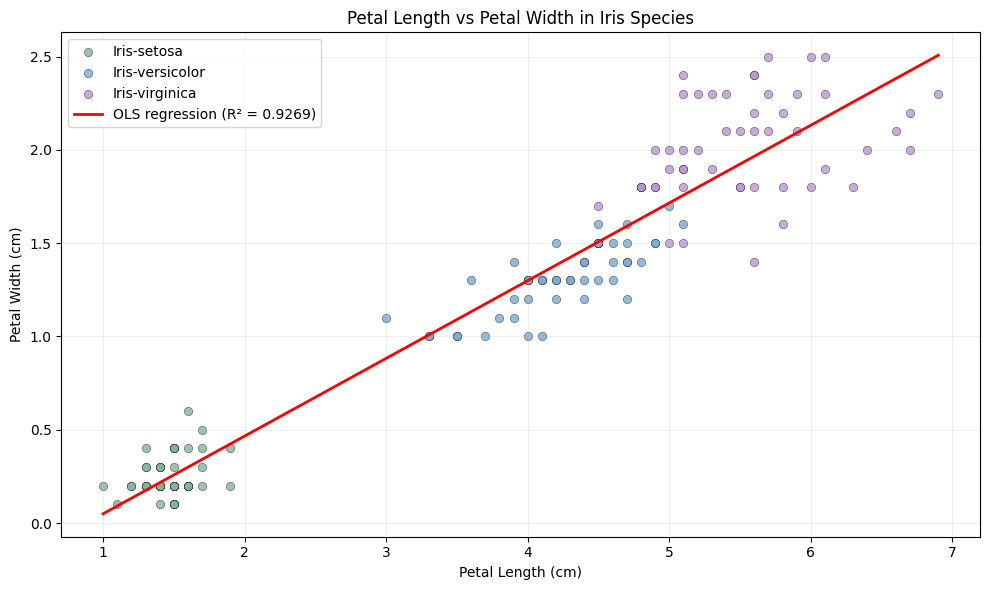

In [6]:

# Figure 2: Petal Length vs Petal Width

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))

colors = {
    "Iris-setosa": "#80B49A",
    "Iris-versicolor": "#77A9D3",
    "Iris-virginica": "#B996D2"
}

# Scatter plot for each species
for species, color in colors.items():
    subset = df[df["species"] == species]
    plt.scatter(
        subset["petal_length"],
        subset["petal_width"],
        label=species,
        color=color,
        alpha=0.8,
        edgecolors="black",
        linewidths=0.3
    )

# Draw regression line
x_line = np.linspace(x.min(), x.max(), 200)
y_line = slope * x_line + intercept

plt.plot(
    x_line, y_line,
    color="red",
    linewidth=2,
    label=f"OLS regression (R² = {r_squared:.4f})"
)

plt.title("Petal Length vs Petal Width in Iris Species")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

# Export as PDF
plt.savefig("Figure2_Linear_Regression.pdf",
            format="pdf", bbox_inches="tight")

plt.show()
